# A5v2. 5G NR tarmog‘i uchun resource grid, CRB–PRB mapping va PRB ajratilishini modellashtirish

**Muhit:** Python + Google Colab  
**Davomiyligi:** 2 soat  
**Variant:** `VARIANT = 1..15`  

Model 3GPP terminologiyasidagi Point A → CRB → BWP → PRB zanjiri, standart N_RB/minimum guardband lookup, RE/s numerology tahlili va ikki pedagogik allocation siyosatini qo‘llaydi.

## 1. Model funksiyalari

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FR1_NRB={15:{20:106,40:216,50:270},30:{20:51,40:106,50:133},60:{20:24,40:51,50:65}}
FR1_MIN_GUARD_KHZ={15:{20:452.5,40:552.5,50:692.5},30:{20:805.0,40:905.0,50:1045.0},60:{20:1330.0,40:1610.0,50:1570.0}}
DATA_RE_FRACTION=0.82
VARIANTS=[{'variant': 1, 'bandwidth_mhz': 40, 'mu': 1, 'bwp_target_mhz': 20, 'n_ue': 8, 'demand_min_mbps': 5.0, 'demand_max_mbps': 12.0, 'eta_min': 1.4, 'eta_max': 4.8, 'seed': 401}, {'variant': 2, 'bandwidth_mhz': 20, 'mu': 0, 'bwp_target_mhz': 10, 'n_ue': 6, 'demand_min_mbps': 3.0, 'demand_max_mbps': 9.0, 'eta_min': 1.2, 'eta_max': 4.2, 'seed': 402}, {'variant': 3, 'bandwidth_mhz': 50, 'mu': 1, 'bwp_target_mhz': 25, 'n_ue': 10, 'demand_min_mbps': 4.0, 'demand_max_mbps': 11.0, 'eta_min': 1.0, 'eta_max': 4.5, 'seed': 403}, {'variant': 4, 'bandwidth_mhz': 40, 'mu': 0, 'bwp_target_mhz': 20, 'n_ue': 7, 'demand_min_mbps': 4.0, 'demand_max_mbps': 10.0, 'eta_min': 1.5, 'eta_max': 5.0, 'seed': 404}, {'variant': 5, 'bandwidth_mhz': 20, 'mu': 1, 'bwp_target_mhz': 12, 'n_ue': 9, 'demand_min_mbps': 2.5, 'demand_max_mbps': 8.0, 'eta_min': 0.9, 'eta_max': 4.0, 'seed': 405}, {'variant': 6, 'bandwidth_mhz': 50, 'mu': 0, 'bwp_target_mhz': 30, 'n_ue': 12, 'demand_min_mbps': 4.0, 'demand_max_mbps': 10.0, 'eta_min': 1.3, 'eta_max': 4.7, 'seed': 406}, {'variant': 7, 'bandwidth_mhz': 40, 'mu': 1, 'bwp_target_mhz': 25, 'n_ue': 8, 'demand_min_mbps': 6.0, 'demand_max_mbps': 14.0, 'eta_min': 1.8, 'eta_max': 5.2, 'seed': 407}, {'variant': 8, 'bandwidth_mhz': 20, 'mu': 0, 'bwp_target_mhz': 15, 'n_ue': 10, 'demand_min_mbps': 2.0, 'demand_max_mbps': 7.0, 'eta_min': 1.0, 'eta_max': 4.4, 'seed': 408}, {'variant': 9, 'bandwidth_mhz': 50, 'mu': 1, 'bwp_target_mhz': 35, 'n_ue': 6, 'demand_min_mbps': 7.0, 'demand_max_mbps': 15.0, 'eta_min': 2.0, 'eta_max': 5.4, 'seed': 409}, {'variant': 10, 'bandwidth_mhz': 40, 'mu': 0, 'bwp_target_mhz': 15, 'n_ue': 11, 'demand_min_mbps': 2.5, 'demand_max_mbps': 8.5, 'eta_min': 0.8, 'eta_max': 4.0, 'seed': 410}, {'variant': 11, 'bandwidth_mhz': 20, 'mu': 1, 'bwp_target_mhz': 10, 'n_ue': 7, 'demand_min_mbps': 4.0, 'demand_max_mbps': 11.0, 'eta_min': 1.1, 'eta_max': 4.6, 'seed': 411}, {'variant': 12, 'bandwidth_mhz': 50, 'mu': 0, 'bwp_target_mhz': 25, 'n_ue': 9, 'demand_min_mbps': 5.0, 'demand_max_mbps': 12.0, 'eta_min': 1.6, 'eta_max': 5.1, 'seed': 412}, {'variant': 13, 'bandwidth_mhz': 40, 'mu': 1, 'bwp_target_mhz': 30, 'n_ue': 12, 'demand_min_mbps': 4.5, 'demand_max_mbps': 13.0, 'eta_min': 1.0, 'eta_max': 4.8, 'seed': 413}, {'variant': 14, 'bandwidth_mhz': 20, 'mu': 0, 'bwp_target_mhz': 12, 'n_ue': 6, 'demand_min_mbps': 3.0, 'demand_max_mbps': 10.0, 'eta_min': 1.3, 'eta_max': 4.3, 'seed': 414}, {'variant': 15, 'bandwidth_mhz': 50, 'mu': 1, 'bwp_target_mhz': 40, 'n_ue': 11, 'demand_min_mbps': 6.0, 'demand_max_mbps': 14.0, 'eta_min': 1.4, 'eta_max': 5.3, 'seed': 415}]

def numerology_params(mu):
    mu=int(mu)
    if mu not in (0,1,2): raise ValueError('mu must be 0, 1 or 2')
    scs=15*(2**mu)
    return dict(mu=mu,scs_khz=scs,slot_duration_ms=1/(2**mu),symbols_per_slot=14,slots_per_subframe=2**mu,slots_per_second=1000*(2**mu),rb_bandwidth_khz=12*scs,rb_bandwidth_mhz=12*scs/1000,re_per_prb_slot=168)

def fr1_nrb(bw,scs): return int(FR1_NRB[int(scs)][int(bw)])
def min_guardband_khz_per_side(bw,scs): return float(FR1_MIN_GUARD_KHZ[int(scs)][int(bw)])
def carrier_metrics(bw,scs):
    bw=float(bw); scs=int(scs); n=fr1_nrb(bw,scs); rb=12*scs/1000; occ=n*rb; side=(bw-occ)*1000/2; mg=min_guardband_khz_per_side(bw,scs)
    return dict(n_rb=n,rb_bandwidth_mhz=rb,occupied_bandwidth_mhz=occ,simple_margin_per_side_khz=side,minimum_guardband_khz_per_side=mg,guard_margin_above_min_khz_per_side=side-mg)
def bwp_from_target_mhz(bw,scs,target):
    cm=carrier_metrics(bw,scs); n=max(1,min(int(math.floor(float(target)/cm['rb_bandwidth_mhz']+1e-12)),cm['n_rb'])); start=(cm['n_rb']-n)//2
    return dict(bwp_target_mhz=float(target),bwp_n_rb=n,bwp_start_crb=start,bwp_end_crb=start+n-1,bwp_occupied_mhz=n*cm['rb_bandwidth_mhz'])
def prb_to_crb(prb,bwp_start_crb): return int(prb)+int(bwp_start_crb)
def crb_to_prb(crb,bwp_start_crb,bwp_n_rb):
    p=int(crb)-int(bwp_start_crb)
    if p<0 or p>=int(bwp_n_rb): raise ValueError('CRB outside BWP')
    return p
def jain_index(x):
    x=np.asarray(x,float); d=x.size*np.sum(x*x); return 0.0 if d<=0 else float(np.sum(x)**2/d)
def prepare_scenario(v):
    v=dict(v); p=numerology_params(v['mu']); cm=carrier_metrics(v['bandwidth_mhz'],p['scs_khz']); bwp=bwp_from_target_mhz(v['bandwidth_mhz'],p['scs_khz'],v['bwp_target_mhz']); rng=np.random.default_rng(v['seed']); n=v['n_ue']; demand=rng.uniform(v['demand_min_mbps'],v['demand_max_mbps'],n); eta=rng.uniform(v['eta_min'],v['eta_max'],n); cap=eta*p['rb_bandwidth_mhz']*DATA_RE_FRACTION; req=np.ceil(demand/cap).astype(int); re_rate=bwp['bwp_n_rb']*168*p['slots_per_second']
    return {**v,**p,**bwp,'carrier_n_rb':cm['n_rb'],'carrier_occupied_mhz':cm['occupied_bandwidth_mhz'],'simple_margin_per_side_khz':cm['simple_margin_per_side_khz'],'minimum_guardband_khz_per_side':cm['minimum_guardband_khz_per_side'],'guard_margin_above_min_khz_per_side':cm['guard_margin_above_min_khz_per_side'],'re_rate_million_per_s':re_rate/1e6,'demand_mbps':demand,'eta_bps_hz':eta,'capacity_per_prb_mbps':cap,'required_prbs':req}
def _equal_share(req,n_av):
    req=np.asarray(req,int); a=np.zeros(len(req),int); owners=[]; ptr=0
    for _ in range(int(n_av)):
        if not np.any(a<req): break
        for k in range(len(req)):
            i=(ptr+k)%len(req)
            if a[i]<req[i]: a[i]+=1; owners.append(i+1); ptr=(i+1)%len(req); break
    return a,np.asarray(owners,int)
def _demand_aware(req,n_av):
    req=np.asarray(req,int); total=req.sum()
    if total<=n_av: a=req.copy()
    else:
        raw=req*n_av/total; a=np.minimum(np.floor(raw).astype(int),req); rem=n_av-a.sum(); frac=raw-np.floor(raw)
        while rem>0:
            cand=np.where(a<req)[0]
            if cand.size==0: break
            i=max(cand,key=lambda z:(frac[z],req[z]-a[z],-z)); a[i]+=1; rem-=1
    owners=np.concatenate([np.repeat(i+1,c) for i,c in enumerate(a)]) if a.sum() else np.array([],int)
    return a,owners
def allocate_policy(sc,policy):
    a,owners=_equal_share(sc['required_prbs'],sc['bwp_n_rb']) if policy=='Equal Share' else _demand_aware(sc['required_prbs'],sc['bwp_n_rb']); raw=a*sc['capacity_per_prb_mbps']; thr=np.minimum(raw,sc['demand_mbps']); sat=thr/sc['demand_mbps']; unmet=sc['demand_mbps']-thr; k=dict(served_throughput_mbps=thr.sum(),mean_satisfaction_pct=100*sat.mean(),p5_satisfaction_pct=100*np.percentile(sat,5),min_satisfaction_pct=100*sat.min(),satisfaction_jain=jain_index(sat),total_unmet_demand_mbps=unmet.sum(),allocated_prbs=a.sum(),unused_bwp_prbs=sc['bwp_n_rb']-a.sum(),bwp_utilization_pct=100*a.sum()/sc['bwp_n_rb'])
    return dict(allocated_prbs=a,prb_owner_ue=owners,throughput_mbps=thr,satisfaction=sat,unmet_demand_mbps=unmet,kpi=k)
def results_tables(v):
    sc=prepare_scenario(v); ue=pd.DataFrame({'UE':np.arange(1,v['n_ue']+1),'Demand_Mbps':sc['demand_mbps'],'Eta_bps_Hz':sc['eta_bps_hz'],'Capacity_per_PRB_Mbps':sc['capacity_per_prb_mbps'],'Required_PRBs':sc['required_prbs']}); rows=[]; ar=[]; res={}
    for pol in ('Equal Share','Demand-Aware'):
        r=allocate_policy(sc,pol); res[pol]=r; rows.append({'Policy':pol,**r['kpi']})
        for i in range(v['n_ue']): ar.append({'Policy':pol,'UE':i+1,'Demand_Mbps':sc['demand_mbps'][i],'Required_PRBs':sc['required_prbs'][i],'Allocated_PRBs':r['allocated_prbs'][i],'Throughput_Mbps':r['throughput_mbps'][i],'Satisfaction_pct':100*r['satisfaction'][i]})
    return sc,ue,pd.DataFrame(rows),pd.DataFrame(ar),res
def numerology_sensitivity(v):
    base=prepare_scenario(v); rows=[]
    for mu in (0,1,2):
        vv=dict(v); vv['mu']=mu; p=numerology_params(mu); cm=carrier_metrics(vv['bandwidth_mhz'],p['scs_khz']); b=bwp_from_target_mhz(vv['bandwidth_mhz'],p['scs_khz'],vv['bwp_target_mhz']); cap=base['eta_bps_hz']*p['rb_bandwidth_mhz']*DATA_RE_FRACTION; req=np.ceil(base['demand_mbps']/cap).astype(int); sc={**base,**p,**b,'carrier_n_rb':cm['n_rb'],'minimum_guardband_khz_per_side':cm['minimum_guardband_khz_per_side'],'capacity_per_prb_mbps':cap,'required_prbs':req,'re_rate_million_per_s':b['bwp_n_rb']*168*p['slots_per_second']/1e6}
        for pol in ('Equal Share','Demand-Aware'):
            r=allocate_policy(sc,pol); rows.append({'mu':mu,'SCS_kHz':p['scs_khz'],'slot_ms':p['slot_duration_ms'],'slots_per_s':p['slots_per_second'],'PRB_BW_kHz':p['rb_bandwidth_khz'],'carrier_N_RB':cm['n_rb'],'min_guard_kHz_side':cm['minimum_guardband_khz_per_side'],'BWP_N_RB':b['bwp_n_rb'],'RE_rate_MRE_s':sc['re_rate_million_per_s'],'Policy':pol,**r['kpi']})
    return pd.DataFrame(rows)
def bwp_sensitivity(v):
    base=prepare_scenario(v); rows=[]
    for f in (.5,.75,1.0):
        vv=dict(v); vv['bwp_target_mhz']=v['bwp_target_mhz']*f; sc=prepare_scenario(vv); sc['demand_mbps']=base['demand_mbps']; sc['eta_bps_hz']=base['eta_bps_hz']; sc['capacity_per_prb_mbps']=base['capacity_per_prb_mbps']; sc['required_prbs']=base['required_prbs']
        for pol in ('Equal Share','Demand-Aware'):
            r=allocate_policy(sc,pol); rows.append({'Scale':f,'BWP_target_MHz':vv['bwp_target_mhz'],'BWP_N_RB':sc['bwp_n_rb'],'BWP_start_CRB':sc['bwp_start_crb'],'BWP_end_CRB':sc['bwp_end_crb'],'Policy':pol,**r['kpi']})
    return pd.DataFrame(rows)

## 2. Variant, carrier va BWP parametrlarini hisoblash

In [2]:
VARIANT=1
v=dict(VARIANTS[VARIANT-1])
sc,ue_df,kpi_df,alloc_df,results=results_tables(v)
carrier_df=pd.DataFrame([{'mu':sc['mu'],'SCS_kHz':sc['scs_khz'],'slot_ms':sc['slot_duration_ms'],'slots_per_s':sc['slots_per_second'],'PRB_BW_kHz':sc['rb_bandwidth_khz'],'carrier_N_RB':sc['carrier_n_rb'],'occupied_MHz':sc['carrier_occupied_mhz'],'simple_margin_side_kHz':sc['simple_margin_per_side_khz'],'3GPP_min_guard_side_kHz':sc['minimum_guardband_khz_per_side'],'BWP_N_RB':sc['bwp_n_rb'],'BWP_start_CRB':sc['bwp_start_crb'],'BWP_end_CRB':sc['bwp_end_crb'],'RE_rate_MRE_s':sc['re_rate_million_per_s']}])
print('Variant:',VARIANT)
display(carrier_df.round(4)); display(ue_df.round(4))

Variant: 1


,mu,SCS_kHz,slot_ms,slots_per_s,PRB_BW_kHz,carrier_N_RB,occupied_MHz,simple_margin_side_kHz,3GPP_min_guard_side_kHz,BWP_N_RB,BWP_start_CRB,BWP_end_CRB,RE_rate_MRE_s
0,1,30,0.5,2000,360,106,38.16,920.0,905.0,55,25,79,18.48


,UE,Demand_Mbps,Eta_bps_Hz,Capacity_per_PRB_Mbps,Required_PRBs
0,1,9.8537,3.2321,0.9541,11
1,2,7.6924,2.2519,0.6648,12
2,3,5.4083,4.2824,1.2642,5
3,4,10.9816,4.5032,1.3293,9
4,5,11.3797,2.0635,0.6091,19
5,6,9.1524,4.4346,1.3091,7
6,7,10.8170,1.5533,0.4585,24
7,8,10.8490,3.5931,1.0607,11


## 3. Equal Share va Demand-Aware allocation

In [3]:
display(kpi_df.round(4)); display(alloc_df.round(4))
for pol in ('Equal Share','Demand-Aware'):
    print(pol, 'PRB->CRB example:', [(p,prb_to_crb(p,sc['bwp_start_crb']),int(results[pol]['prb_owner_ue'][p])) for p in range(min(6,len(results[pol]['prb_owner_ue'])))])

,Policy,served_throughput_mbps,mean_satisfaction_pct,p5_satisfaction_pct,min_satisfaction_pct,satisfaction_jain,total_unmet_demand_mbps,allocated_prbs,unused_bwp_prbs,bwp_utilization_pct
0,Equal Share,51.0507,69.7839,32.4015,29.6723,0.8893,25.0833,55,0,100.0
1,Demand-Aware,46.4570,60.5647,48.5346,46.7492,0.9389,29.6771,55,0,100.0


,Policy,UE,Demand_Mbps,Required_PRBs,Allocated_PRBs,Throughput_Mbps,Satisfaction_pct
0,Equal Share,1,9.8537,11,8,7.6329,77.4626
1,Equal Share,2,7.6924,12,7,4.6533,60.4919
2,Equal Share,3,5.4083,5,5,5.4083,100.0000
3,Equal Share,4,10.9816,9,7,9.3054,84.7364
4,Equal Share,5,11.3797,19,7,4.2640,37.4700
5,Equal Share,6,9.1524,7,7,9.1524,100.0000
6,Equal Share,7,10.8170,24,7,3.2097,29.6723
7,Equal Share,8,10.8490,11,7,7.4248,68.4378
8,Demand-Aware,1,9.8537,11,6,5.7247,58.0970
9,Demand-Aware,2,7.6924,12,6,3.9885,51.8502


Equal Share PRB->CRB example: [(0, 25, 1), (1, 26, 2), (2, 27, 3), (3, 28, 4), (4, 29, 5), (5, 30, 6)]
Demand-Aware PRB->CRB example: [(0, 25, 1), (1, 26, 1), (2, 27, 1), (3, 28, 1), (4, 29, 1), (5, 30, 1)]


## 4. Resource-grid, Point A/CRB/BWP va PRB ownership vizualizatsiyasi

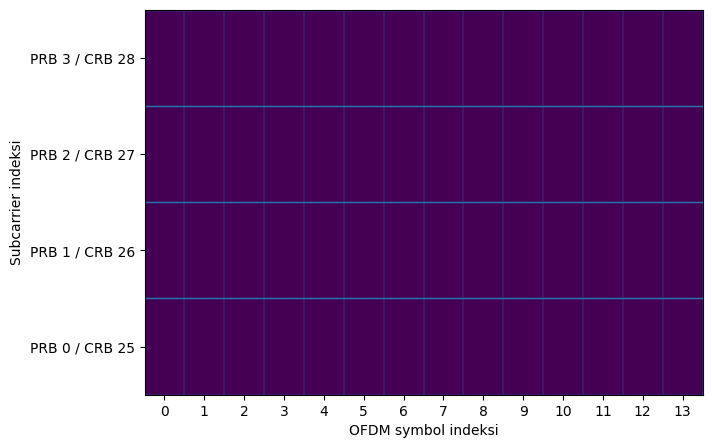

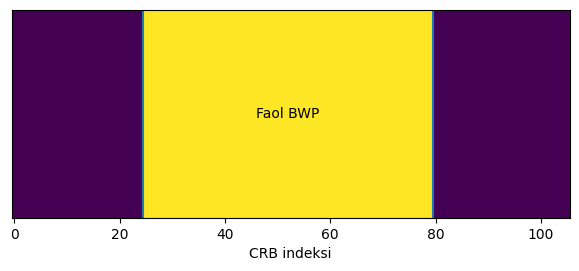

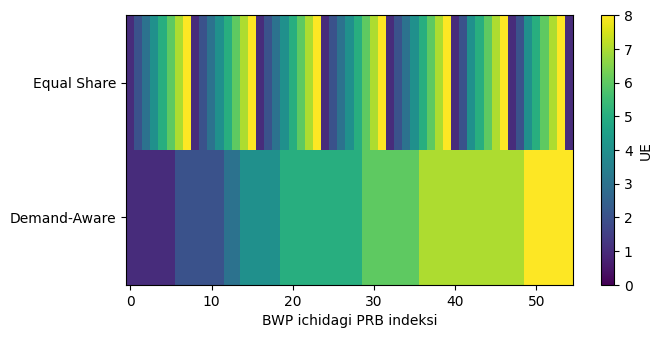

In [4]:
nprb=4; nsc=48; nsym=14
fig,ax=plt.subplots(figsize=(7.2,5)); ax.imshow(np.zeros((nsc,nsym)),aspect='auto',origin='lower',interpolation='nearest')
for y in range(0,nsc+1,12): ax.axhline(y-.5,linewidth=1.0)
for x in range(nsym+1): ax.axvline(x-.5,linewidth=.3)
ax.set_xlabel('OFDM symbol indeksi'); ax.set_ylabel('Subcarrier indeksi'); ax.set_xticks(range(nsym)); ax.set_yticks([5.5+12*i for i in range(nprb)],labels=[f'PRB {i} / CRB {sc["bwp_start_crb"]+i}' for i in range(nprb)]); plt.show()

fig,ax=plt.subplots(figsize=(7.2,2.7)); carr=np.zeros((1,sc['carrier_n_rb'])); carr[:,sc['bwp_start_crb']:sc['bwp_end_crb']+1]=1; ax.imshow(carr,aspect='auto',interpolation='nearest'); ax.set_yticks([]); ax.set_xlabel('CRB indeksi'); ax.axvline(sc['bwp_start_crb']-.5); ax.axvline(sc['bwp_end_crb']+.5); ax.text((sc['bwp_start_crb']+sc['bwp_end_crb'])/2,0,'Faol BWP',ha='center',va='center'); plt.show()

fig,ax=plt.subplots(figsize=(7.2,3.5)); mat=np.zeros((2,sc['bwp_n_rb']))
for rr,pol in enumerate(('Equal Share','Demand-Aware')): mat[rr,:len(results[pol]['prb_owner_ue'])]=results[pol]['prb_owner_ue']
im=ax.imshow(mat,aspect='auto',interpolation='nearest',vmin=0,vmax=v['n_ue']); ax.set_yticks([0,1],labels=['Equal Share','Demand-Aware']); ax.set_xlabel('BWP ichidagi PRB indeksi'); plt.colorbar(im,ax=ax,label='UE'); plt.show()

## 5. Numerologiya va BWP sensitivity

,mu,SCS_kHz,slot_ms,slots_per_s,PRB_BW_kHz,carrier_N_RB,min_guard_kHz_side,BWP_N_RB,RE_rate_MRE_s,Policy,served_throughput_mbps,mean_satisfaction_pct,p5_satisfaction_pct,min_satisfaction_pct,satisfaction_jain,total_unmet_demand_mbps,allocated_prbs,unused_bwp_prbs,bwp_utilization_pct
0,0,15,1.00,1000,180,216,552.5,111,18.648,Equal Share,51.8753,70.8099,33.3383,29.6723,0.8935,24.2588,111,0,100.0
1,0,15,1.00,1000,180,216,552.5,111,18.648,Demand-Aware,44.5928,58.3984,55.0676,54.4734,0.9965,31.5412,111,0,100.0
2,1,30,0.50,2000,360,106,905.0,55,18.480,Equal Share,51.0507,69.7839,32.4015,29.6723,0.8893,25.0833,55,0,100.0
3,1,30,0.50,2000,360,106,905.0,55,18.480,Demand-Aware,46.4570,60.5647,48.5346,46.7492,0.9389,29.6771,55,0,100.0
4,2,60,0.25,4000,720,51,1610.0,27,18.144,Equal Share,49.6186,68.1836,27.7727,25.4334,0.8722,26.5155,27,0,100.0
5,2,60,0.25,4000,720,51,1610.0,27,18.144,Demand-Aware,46.0704,59.2259,48.1904,46.7492,0.9418,30.0636,27,0,100.0


,Scale,BWP_target_MHz,BWP_N_RB,BWP_start_CRB,BWP_end_CRB,Policy,served_throughput_mbps,mean_satisfaction_pct,p5_satisfaction_pct,min_satisfaction_pct,satisfaction_jain,total_unmet_demand_mbps,allocated_prbs,unused_bwp_prbs,bwp_utilization_pct
0,0.50,10.0,27,39,65,Equal Share,25.8325,38.0159,13.8864,12.7167,0.7282,50.3016,27,0,100.0
1,0.50,10.0,27,39,65,Demand-Aware,22.9947,30.1624,23.6671,23.3746,0.8936,53.1394,27,0,100.0
2,0.75,15.0,41,32,72,Equal Share,38.2906,53.7738,23.1439,21.1945,0.8389,37.8434,41,0,100.0
3,0.75,15.0,41,32,72,Demand-Aware,31.8033,41.7486,31.3046,28.6064,0.9628,44.3308,41,0,100.0
4,1.00,20.0,55,25,79,Equal Share,51.0507,69.7839,32.4015,29.6723,0.8893,25.0833,55,0,100.0
5,1.00,20.0,55,25,79,Demand-Aware,46.4570,60.5647,48.5346,46.7492,0.9389,29.6771,55,0,100.0


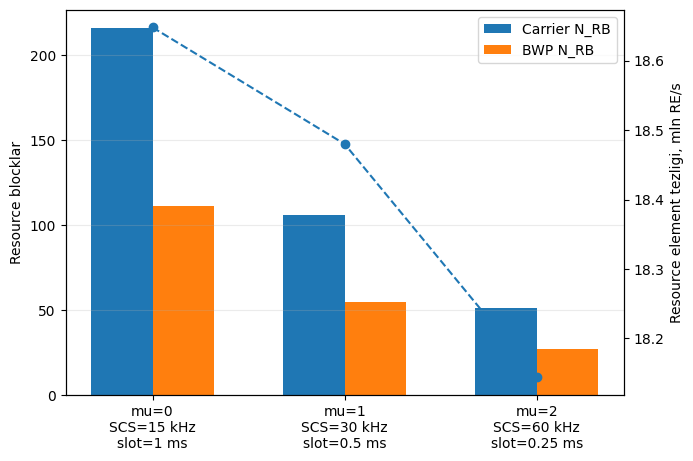

In [5]:
num_df=numerology_sensitivity(v); bwp_df=bwp_sensitivity(v)
display(num_df.round(4)); display(bwp_df.round(4))
nd=num_df[num_df['Policy']=='Equal Share'].sort_values('mu'); x=np.arange(len(nd)); w=.32
fig,ax=plt.subplots(figsize=(7.2,5)); ax.bar(x-w/2,nd['carrier_N_RB'],width=w,label='Carrier N_RB'); ax.bar(x+w/2,nd['BWP_N_RB'],width=w,label='BWP N_RB'); ax.set_ylabel('Resource blocklar'); ax.set_xticks(x,labels=[f'mu={int(r.mu)}\nSCS={int(r.SCS_kHz)} kHz\nslot={r.slot_ms:g} ms' for _,r in nd.iterrows()]); ax.legend(); ax.grid(axis='y',alpha=.25); ax2=ax.twinx(); ax2.plot(x,nd['RE_rate_MRE_s'],marker='o',linestyle='--'); ax2.set_ylabel('Resource element tezligi, mln RE/s'); plt.show()

## 6. CSV eksport va sanity-checklar

In [6]:
prefix=f'A5v2_variant_{VARIANT:02d}'
ue_df.to_csv(prefix+'_ue_parameters.csv',index=False); kpi_df.to_csv(prefix+'_kpi.csv',index=False); alloc_df.to_csv(prefix+'_allocations.csv',index=False); num_df.to_csv(prefix+'_numerology_sensitivity.csv',index=False); bwp_df.to_csv(prefix+'_bwp_sensitivity.csv',index=False)
for pol,r in results.items():
    assert r['allocated_prbs'].sum()<=sc['bwp_n_rb']; assert np.all(r['throughput_mbps']<=sc['demand_mbps']+1e-9); assert 0<=r['kpi']['satisfaction_jain']<=1
assert sc['simple_margin_per_side_khz']>=sc['minimum_guardband_khz_per_side']
assert prb_to_crb(0,sc['bwp_start_crb'])==sc['bwp_start_crb']
print(prefix)

A5v2_variant_01


## 7. Talaba xulosasi

6–8 gapda Point A–CRB–BWP–PRB munosabatini, standard minimum guardband bilan simple margin farqini, μ oshganda PRB soni kamayib slots/s oshishini va RE/s nega deyarli saqlanishini, shuningdek ikki allocation siyosatining throughput–fairness trade-offini izohlang.